RFM Data:
   CustomerID  Recency  Frequency  Monetary
0     12346.0      326          1  77183.60
1     12347.0        2          7   4310.00
2     12348.0       75          4   1797.24
3     12349.0       19          1   1757.55
4     12350.0      310          1    334.40


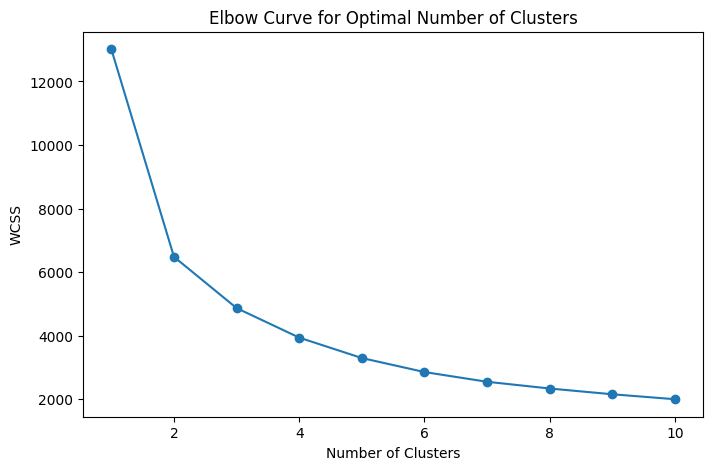


Customer Segments:
   CustomerID  Recency  Frequency  Monetary  Cluster
0     12346.0      326          1  77183.60        2
1     12347.0        2          7   4310.00        1
2     12348.0       75          4   1797.24        2
3     12349.0       19          1   1757.55        0
4     12350.0      310          1    334.40        3

Number of Customers in Each Segment:
Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64

Segment Summary:
         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                     
0              837        18.12           2.15        551.82
1              716        12.13          13.71       8074.27
2             1173        71.08           4.08       1802.83
3             1612       182.50           1.32        343.45


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

data = pd.read_csv("OnlineRetail.csv", encoding="latin1")

data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
data = data[(data['Quantity'] > 0) &
            (data['UnitPrice'] > 0) &
            (data['CustomerID'].notna())]

data['Amount'] = data['Quantity'] * data['UnitPrice']

snapshot_date = data['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = data.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Amount', 'sum')
).reset_index()

print("RFM Data:")
print(rfm.head())

# Log transformation to reduce skewness
rfm_features = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

# Standardization
scaler = StandardScaler()
X = scaler.fit_transform(rfm_features)

# Elbow Method
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Curve for Optimal Number of Clusters')
plt.show()

# Applying K-Means with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(X)

print("\nCustomer Segments:")
print(rfm.head())

print("\nNumber of Customers in Each Segment:")
print(rfm['Cluster'].value_counts().sort_index())

# Segment summary
summary = rfm.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

print("\nSegment Summary:")
print(summary)